中心点含耗散保真度 F = 0.999776   (t_tot = 0.344 µs)
Ω1max = 2π×40 MHz, Δ1max = 2π×24 MHz, V0 = 2π×527 MHz, γr = 2π×0.0000 kHz
  行 21/21 完成 (47s)
±10% 网格: 中心 F = 0.999776, 最小 F = 0.979312, 最大 F = 0.999776
图已保存: fig2e_2bit_pulse.png


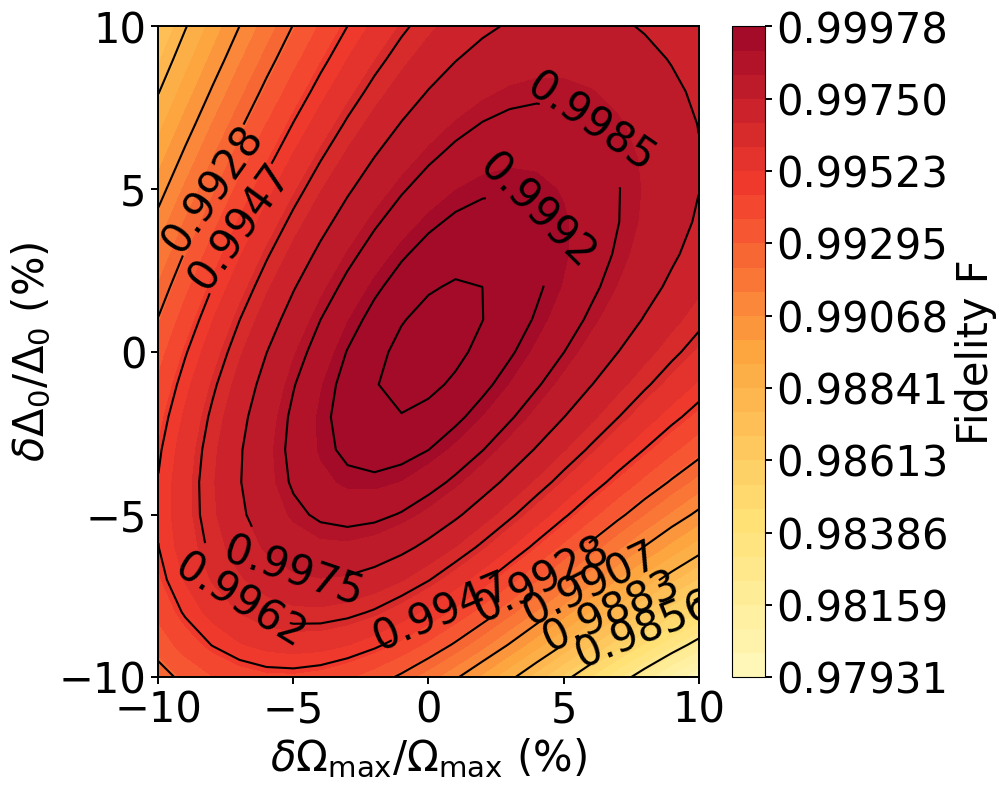

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from itertools import product

# ==================== 物理参数 (2π×MHz 与 µs) ====================
Omega10 = 2*np.pi*100.0        # Ω10 = 2π×100 MHz ≈ 628.32 rad/µs
gamma_r = 1.0/540.0            # 里德堡态总耗散率 (Cs |107P3/2>), 540 µs 寿命

# ==================== 脉冲参数：替换为 "2比特 (2).txt" 的优化脉冲 ====================
# 换算到以 Ω10(=Ω0) 为能量单位、1/Ω10 为时间单位的无量纲量:
tau_tot = 216.2                # 无量纲总时长 → t_tot = 215.7/Ω10 ≈ 0.343 µs
OM1max  = 0.3997                # Ωmax = 1.0 Ω10  → 2π×100 MHz
DE1max  = 0.2356               # Δ0 峰值 = 1.3829 Ω10 → 2π×138.29 MHz
sR      = 24.19                # Ω 包络宽度 (无量纲)
sD      = 45.08                # Δ 包络宽度 (无量纲)
PF      = 0.500                # πg 位置 (t_π = PF·tau_tot)
# 注意: V0 是优化脉冲的配套参数 (该文件为 4.12 Ω0)，随脉冲一并替换；
#       若坚持沿用原 RAP 脚本的 V0 = 0.70，请把下行改回 0.70。
V0      = 5.2715                 # 相互作用 = 4.12 Ω10 → 2π×412 MHz

# 无量纲耗散率
Gamma = gamma_r/Omega10
Gd = 7*Gamma/8                 # 退相位
Gs = Gamma/16                  # 自发辐射 (r→0, r→1 各一通道)

# ==================== 9 维 Hilbert 空间 ====================
st = [''.join(p) for p in product('01r', repeat=2)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)

Cc = np.zeros((d, d))                        # 耦合 Σ_a (|r><1|+h.c.)/2
for s, i in idx.items():
    for a in range(2):
        if s[a] == '1':
            Cc[idx[s[:a]+'r'+s[a+1:]], i] = 0.5
        elif s[a] == 'r':
            Cc[idx[s[:a]+'1'+s[a+1:]], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Dr = np.diag(n_r)                            # 失谐项 (|rr⟩ 计 2Δ)
Err = np.zeros((d, d)); Err[idx['rr'], idx['rr']] = 1.0

D_deph = np.zeros((d, d))                    # 退相位跳跃项掩膜
for a in range(2):
    m = np.array([1.0 if s[a] == 'r' else 0.0 for s in st])
    D_deph += np.outer(m, m)
D_deph *= Gd
anti = Gamma*(n_r[:, None] + n_r[None, :])   # 反对易子因子 Σ L†L = γr·n_r
spont = []                                   # 自发辐射 (src→dst) 索引对
for a in range(2):
    for ch in '01':
        src = np.array([i for s, i in idx.items() if s[a] == 'r'])
        dst = np.array([idx[s[:a]+ch+s[a+1:]] for s, i in idx.items()
                       if s[a] == 'r']).ravel()      # (3,) 而非 (3,1)
        spont.append((src, dst))
g_perm = np.array([idx[s.replace('0', '_').replace('1', '0').replace('_', '1')]
                   for s in st])             # πg 置换 (0↔1)

psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)


def pulse(tau):
    """优化脉冲 (2比特 (2).txt): 归一化包络, |Ω| 峰值=1, Δ 峰值=1
       Ω(t) = -√(2e)·xR·e^{-xR²},   Δ(t) = e·xD²·e^{-xD²}
       两段 (πg 前后) 各以段中心 tm 为零点。"""
    tau = np.asarray(tau, float)
    tau_pi = PF*tau_tot
    tm = np.where(tau <= tau_pi, tau_pi/2, tau_pi + (tau_tot - tau_pi)/2)
    xR = (tau - tm)/sR
    xD = (tau - tm)/sD
    Om = -np.sqrt(2*np.e)*xR*np.exp(-xR**2)
    De = np.e*xD**2*np.exp(-xD**2)
    return Om, De


def fidelity(dO=0.0, dD=0.0, dt=0.05, diss=True):
    """dO/dD: Ω1max、Δ1max 的相对误差 (%)。支持批量 (广播) 计算。"""
    dO = np.atleast_1d(np.asarray(dO, float))
    dD = np.atleast_1d(np.asarray(dD, float))
    OmM, DeM = OM1max*(1+dO/100), DE1max*(1+dD/100)   # 有效峰值
    DrG, CcG, ErrG = Dr[None], Cc[None], V0*Err[None]
    DdG, antiG = (D_deph[None] if diss else 0.0), (anti[None] if diss else 0.0)

    def deriv(rho, Om, De):
        H = (De*DeM)[:, None, None]*DrG + (Om*OmM)[:, None, None]*CcG + ErrG
        dr = -1j*(H@rho - rho@H)
        if diss:
            dr = dr + DdG*rho
            for src, dst in spont:
                dr[:, dst, dst] += Gs*rho[:, src, src]
            dr = dr - 0.5*antiG*rho
        return dr

    N = int(round(tau_tot/dt))
    n_pi = int(round(PF*N))
    rho = np.zeros((dO.size, d, d), complex)
    rho[:, idx['11'], idx['11']] = 1.0
    for n in range(N):
        t0 = n*dt
        Om0, De0 = pulse(t0)
        Omh, Deh = pulse(t0+dt/2)
        Om1, De1 = pulse(t0+dt)
        k1 = deriv(rho, Om0, De0)
        k2 = deriv(rho + 0.5*dt*k1, Omh, Deh)
        k3 = deriv(rho + 0.5*dt*k2, Omh, Deh)
        k4 = deriv(rho + dt*k3, Om1, De1)
        rho = rho + dt*(k1 + 2*k2 + 2*k3 + k4)/6
        if n == n_pi - 1:                    # 中点施加 πg (时间忽略不计)
            rho = rho[:, g_perm[:, None], g_perm[None, :]]
    return np.real(np.einsum('i,gij,j->g', psiT.conj(), rho, psiT))


# ==================== ±10% 鲁棒性扫描 (21×21) ====================
if __name__ == '__main__':
    import time
    t0 = time.time()
    F0 = fidelity()[0]
    print(f"中心点含耗散保真度 F = {F0:.6f}   (t_tot = {tau_tot/Omega10:.3f} µs)")
    print(f"Ω1max = 2π×{OM1max*100:.0f} MHz, Δ1max = 2π×{DE1max*100:.0f} MHz, "
          f"V0 = 2π×{V0*100:.0f} MHz, γr = 2π×{gamma_r/(2*np.pi)*1e-3:.4f} kHz")

    offsets = np.linspace(-10, 10, 21)
    grid = np.zeros((len(offsets), len(offsets)))
    for i, dD in enumerate(offsets):         # 行: δΔ0 误差
        grid[i, :] = fidelity(dO=offsets, dD=dD)   # 列: δΩmax 误差
        print(f"  行 {i+1}/21 完成 ({time.time()-t0:.0f}s)", end='\r')
    print()
    print(f"±10% 网格: 中心 F = {grid[10,10]:.6f}, "
          f"最小 F = {grid.min():.6f}, 最大 F = {grid.max():.6f}")
    np.save('grid_2bit_pulse.npy', grid)

    # ==================== 画鲁棒性等高线图（与第二个程序样式一致） ====================
    cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
        (1.000, 0.976, 0.737),   # 淡黄（低值）
        (1.000, 0.878, 0.451),   # 黄
        (0.992, 0.651, 0.247),   # 橙
        (0.953, 0.231, 0.176),   # 红橙
        (0.624, 0.031, 0.157),   # 深红（高值）
    ])
    FS_LAB = 30
    FS_TCK = 30

    # 根据本次计算结果自动确定填色范围和等高线级别
    f_min, f_max = float(np.nanmin(grid)), float(np.nanmax(grid))
    if np.isclose(f_min, f_max):
        # 极端情况：整个网格值几乎一样，避免 contourf 级别重合
        pad = max(abs(f_min)*1e-6, 1e-9)
        f_min, f_max = f_min - pad, f_max + pad

    fill_levels = np.linspace(f_min, f_max, 28)       # 自适应颜色尺度

    # 非线性自适应分级：等高线越靠近最高保真度越密集
    level_pos = np.linspace(0.0, 1.0, 13)[1:-1]
    line_levels = f_min + (f_max - f_min)*(1.0 - (1.0 - level_pos)**2)

    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(offsets, offsets, grid,
                     levels=fill_levels, cmap=cmap_ref)
    cs = ax.contour(offsets, offsets, grid,
                    levels=line_levels,
                    colors='black', linewidths=1.5)
    ax.clabel(cs, fmt='%.4f', fontsize=30, colors='black', inline_spacing=3)
    cbar = plt.colorbar(cf, ax=ax)
    cbar.set_label('Fidelity F', fontsize=FS_LAB)
    cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)
    ax.set_xlabel(r'$\delta\Omega_{\max}/\Omega_{\max}$ (%)', fontsize=FS_LAB)
    ax.set_ylabel(r'$\delta\Delta_0/\Delta_0$ (%)', fontsize=FS_LAB)
    ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
    for sp in ax.spines.values():
        sp.set_linewidth(1.4)
    plt.tight_layout()
    plt.savefig('fig2e_2bit_pulse.png', dpi=200)
    print("图已保存: fig2e_2bit_pulse.png")
    plt.show()
